In [1]:
TEKST_BREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import bambi as bmb
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

FONT_TEKST = "Libertinus Serif"
FONT_CIJFERS = "Libertinus Math"

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [FONT_TEKST],
    "font.size": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "figure.facecolor": "white",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.01,
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT_TEKST,
    "axes.unicode_minus": False,
})

KLEUR_AS = "#5A5E62"

MACRO = Path("../../data/algemeen/gebeurtenisdata_macro")
UITVOER = Path("../../fig/H6")


def opmaak_assen(ax):
    for kant in ("top", "right"):
        ax.spines[kant].set_visible(False)
    for kant in ("left", "bottom"):
        ax.spines[kant].set_color(KLEUR_AS)

    ax.tick_params(colors="black")
    ax.grid(axis="y")
    ax.set_axisbelow(True)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontfamily(FONT_CIJFERS)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
bestanden = sorted(
    p for p in MACRO.glob("*.xlsx")
    if not p.name.startswith(("~$", "._"))
)

df_macro = pd.concat(
    [pd.read_excel(p) for p in bestanden],
    ignore_index=True
)

print(
    len(bestanden),
    "bestanden,",
    f"{len(df_macro):,}".replace(",", "."),
    "registraties"
)

197 bestanden, 383.125 registraties


In [3]:
PERIODE = (1876, 1939)
WOI = (1914, 1918)

NACHT = {
    "nacht",
    "avondschemering",
    "ochtendschemering",
    "avondschemer",
    "ochtendschemer",
}

KOL_ASTRO = next(
    k for k in ("astro", "astronomical_category")
    if k in df_macro.columns
)

df_pers = df_macro.copy()

df_pers["jaar"] = pd.to_datetime(
    df_pers["E_DATE_clean"],
    errors="coerce"
).dt.year

df_pers["cat"] = (
    df_pers[KOL_ASTRO]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_pers = df_pers[
    df_pers["jaar"].between(*PERIODE)
    & ~df_pers["jaar"].between(*WOI)
    & df_pers["cat"].isin(NACHT | {"dag"})
    & df_pers["district"].notna()
].copy()

# wijken samenvoegen; 8, 9 en 10 vallen weg
df_pers = df_pers[~df_pers["district"].isin([8, 9, 10])].copy()
df_pers["district"] = df_pers["district"].replace({7: 6, 11: 5})
df_pers["nacht"] = df_pers["cat"].isin(NACHT).astype(int)

agg = (
    df_pers
    .groupby(["district", "jaar"])["nacht"]
    .agg(nacht="sum", totaal="size")
    .reset_index()
    .rename(columns={"jaar": "year"})
)

agg["jaar_c"] = (agg["year"] - 1900) / 10
agg["district"] = agg["district"].astype(int).astype("category")

print(
    agg.groupby("district", observed=True)
    .agg(
        jaren=("year", "size"),
        personen=("totaal", "sum"),
        van=("year", "min"),
        tot=("year", "max"),
    )
)

/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_32489/293698970.py:19: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_pers["jaar"] = pd.to_datetime(


          jaren  personen   van   tot
district                             
1            15     10638  1878  1939
3            40     85481  1876  1939
5            27     25706  1876  1939
6            33     53262  1895  1939


In [4]:
FORMULE = "p(nacht, totaal) ~ bs(jaar_c, df=4) + (jaar_c | district)"

model = bmb.Model(
    FORMULE,
    data=agg,
    family="beta_binomial"
)

idata = model.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=1,
    target_accept=0.95,
    random_seed=42,
    idata_kwargs={"log_likelihood": True},
)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, Intercept, bs(jaar_c, df=4), 1|district_sigma, 1|district_offset, jaar_c|district_sigma, jaar_c|district_offset]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 199 seconds.


There were 13 divergences after tuning. Increase `target_accept` or reparameterize.


In [5]:
BEREIK = {
    1: (1879, 1901),
    3: (1877, 1939),
    5: (1876, 1939),
    6: (1895, 1939),
}

JAREN = np.arange(1876, 1940)


def kansen(pred):
    naam = "p" if "p" in pred.posterior else "mu"
    return (
        pred.posterior[naam]
        .stack(s=("chain", "draw"))
        .values
        * 100
    )


def samenvatten(p):
    return {
        "med": np.median(p, axis=1),
        "lo": np.percentile(p, 3, axis=1),
        "hi": np.percentile(p, 97, axis=1),
    }


def voorspel(district):
    van, tot = BEREIK[district]
    jaren = np.arange(van, tot + 1)

    grid = pd.DataFrame({
        "year": jaren,
        "jaar_c": (jaren - 1900) / 10,
        "totaal": 1,
        "district": pd.Categorical(
            [district] * len(jaren),
            categories=agg["district"].cat.categories,
        ),
    })

    pred = model.predict(
        idata,
        data=grid,
        kind="mean",
        inplace=False,
        sample_new_groups=False,
    )

    return {
        "jaren": jaren,
        **samenvatten(kansen(pred)),
    }


def voorspel_totaal():
    grid = pd.DataFrame({
        "year": JAREN,
        "jaar_c": (JAREN - 1900) / 10,
        "totaal": 1,
        "district": pd.Categorical(
            [agg["district"].cat.categories[0]] * len(JAREN),
            categories=agg["district"].cat.categories,
        ),
    })

    pred = model.predict(
        idata,
        data=grid,
        kind="mean",
        inplace=False,
        include_group_specific=False,
    )

    return {
        "jaren": JAREN,
        **samenvatten(kansen(pred)),
    }


resultaten = {
    district: voorspel(district)
    for district in BEREIK
}

totaal = voorspel_totaal()

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


In [6]:
KLEUREN = KLEUR_WIJK

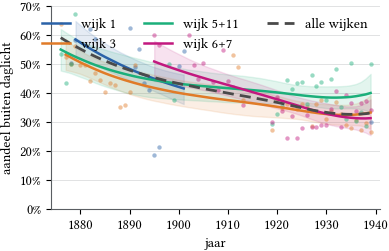

In [7]:
WIJKEN = [1, 3, 5, 6]

LABELS = {
    5: "wijk 5+11",
    6: "wijk 6+7",
}

MIN_N = 10

fig, ax = plt.subplots(
    figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.62)
)

for wijk in WIJKEN:
    r = resultaten[wijk]
    kleur = KLEUREN[wijk]

    sub = agg[agg["district"] == wijk]
    zicht = sub[sub["totaal"] >= MIN_N]

    ax.fill_between(
        r["jaren"],
        r["lo"],
        r["hi"],
        color=kleur,
        alpha=0.12,
        zorder=1,
    )

    ax.scatter(
        zicht["year"],
        zicht["nacht"] / zicht["totaal"] * 100,
        s=10,
        color=kleur,
        alpha=0.45,
        linewidth=0,
        zorder=2,
    )

    ax.plot(
        r["jaren"],
        r["med"],
        color=kleur,
        linewidth=1.8,
        zorder=3,
        label=LABELS.get(wijk, f"wijk {wijk}"),
    )

ax.plot(
    totaal["jaren"],
    totaal["med"],
    color="#4A4A4A",
    linewidth=2,
    linestyle=(0, (4, 2.2)),
    zorder=5,
    label="alle wijken",
)

ax.set_xlabel("jaar")
ax.set_ylabel("aandeel buiten daglicht")

ax.yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%")
)

ax.set_xlim(1874, 1941)
ax.set_ylim(0, 70)

ax.legend(
    frameon=False,
    ncol=3,
    loc="upper right",
    fontsize=CORPS,
)

opmaak_assen(ax)

#fig.savefig(
#    UITVOER / "nachtaandeel_per_wijk.png",
#    dpi=300,
#)

plt.show()

In [8]:
print(1900 + 10 * agg["jaar_c"].median())

1921.0


In [9]:
for wijk in WIJKEN:
    r = resultaten[wijk]

    print(
        f"wijk {wijk}: "
        f"{r['jaren'][0]} = {r['med'][0]:.1f}%  →  "
        f"{r['jaren'][-1]} = {r['med'][-1]:.1f}%"
    )

print(
    f"algemene trend: "
    f"{totaal['jaren'][0]} = {totaal['med'][0]:.1f}%  →  "
    f"{totaal['jaren'][-1]} = {totaal['med'][-1]:.1f}%"
)

wijk 1: 1879 = 58.4%  →  1901 = 41.5%
wijk 3: 1877 = 53.1%  →  1939 = 33.2%
wijk 5: 1876 = 54.9%  →  1939 = 39.9%
wijk 6: 1895 = 50.8%  →  1939 = 31.2%
algemene trend: 1876 = 59.0%  →  1939 = 33.0%


In [10]:
for wijk in WIJKEN:
    r = resultaten[wijk]

    print(
        f"wijk {wijk}: "
        f"{r['jaren'][0]} = {r['med'][0]:.1f}% "
        f"[{r['lo'][0]:.1f}–{r['hi'][0]:.1f}]  →  "
        f"{r['jaren'][-1]} = {r['med'][-1]:.1f}% "
        f"[{r['lo'][-1]:.1f}–{r['hi'][-1]:.1f}]"
    )

print(
    f"algemene trend: "
    f"{totaal['jaren'][0]} = {totaal['med'][0]:.1f}% "
    f"[{totaal['lo'][0]:.1f}–{totaal['hi'][0]:.1f}]  →  "
    f"{totaal['jaren'][-1]} = {totaal['med'][-1]:.1f}% "
    f"[{totaal['lo'][-1]:.1f}–{totaal['hi'][-1]:.1f}]"
)

wijk 1: 1879 = 58.4% [52.1–64.7]  →  1901 = 41.5% [36.1–46.3]
wijk 3: 1877 = 53.1% [47.8–58.6]  →  1939 = 33.2% [27.5–39.2]
wijk 5: 1876 = 54.9% [47.6–62.0]  →  1939 = 39.9% [33.3–46.5]
wijk 6: 1895 = 50.8% [44.1–57.9]  →  1939 = 31.2% [25.4–37.7]
algemene trend: 1876 = 59.0% [45.9–73.1]  →  1939 = 33.0% [17.7–50.6]


In [11]:
FORMULE_FLEX = (
    "p(nacht, totaal) ~ "
    "bs(jaar_c, df=4) + "
    "(bs(jaar_c, df=4) | district)"
)

model_flex = bmb.Model(
    FORMULE_FLEX,
    data=agg,
    family="beta_binomial"
)

idata_flex = model_flex.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=1,
    target_accept=0.95,
    random_seed=42,
    idata_kwargs={"log_likelihood": True},
)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, Intercept, bs(jaar_c, df=4), 1|district_sigma, 1|district_offset, bs(jaar_c, df=4)|district_sigma, bs(jaar_c, df=4)|district_offset]


Output()

Output()

In [12]:
import arviz as az

samenvatting_flex = az.summary(
    idata_flex,
    var_names=["Intercept", "bs(", "sigma", "kappa"],
    filter_vars="like"
)

print(samenvatting_flex.to_string())

print()
print("maximale R-hat:", samenvatting_flex["r_hat"].max())
print("minimale bulk ESS:", samenvatting_flex["ess_bulk"].min())

                                      mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
kappa                               53.459  8.495  38.773   70.094      0.102    0.072    7026.0    6316.0    1.0
Intercept                            0.314  0.268  -0.142    0.862      0.004    0.003    5264.0    4375.0    1.0
bs(jaar_c, df=4)[0]                 -0.165  1.004  -2.131    1.663      0.017    0.014    3778.0    3364.0    1.0
bs(jaar_c, df=4)[1]                 -1.289  1.088  -3.382    0.747      0.025    0.022    2522.0    1910.0    1.0
bs(jaar_c, df=4)[2]                 -0.703  0.955  -2.548    1.347      0.025    0.018    2024.0    1398.0    1.0
bs(jaar_c, df=4)[3]                 -1.018  0.450  -1.723   -0.346      0.015    0.010    2430.0    1521.0    1.0
1|district_sigma                     0.339  0.416   0.000    0.965      0.008    0.006    2704.0    3669.0    1.0
bs(jaar_c, df=4)|district_sigma[0]   1.643  1.426   0.020    3.889      0.025    0.018  

In [13]:
def voorspel_flex(district):
    van, tot = BEREIK[district]
    jaren = np.arange(van, tot + 1)

    grid = pd.DataFrame({
        "year": jaren,
        "jaar_c": (jaren - 1900) / 10,
        "totaal": 1,
        "district": pd.Categorical(
            [district] * len(jaren),
            categories=agg["district"].cat.categories,
        ),
    })

    pred = model_flex.predict(
        idata_flex,
        data=grid,
        kind="mean",
        inplace=False,
        sample_new_groups=False,
    )

    p = kansen(pred)

    return {
        "jaren": jaren,
        **samenvatten(p),
    }


resultaten_flex = {
    district: voorspel_flex(district)
    for district in BEREIK
}

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


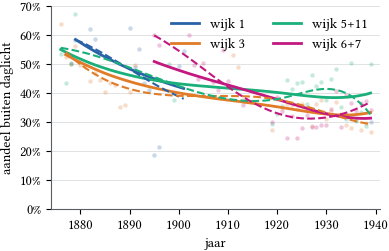

In [14]:
fig, ax = plt.subplots(
    figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.62)
)

for wijk in WIJKEN:
    kleur = KLEUREN[wijk]

    # geobserveerde waarden
    sub = agg[
        (agg["district"] == wijk) &
        (agg["totaal"] >= MIN_N)
    ]

    ax.scatter(
        sub["year"],
        sub["nacht"] / sub["totaal"] * 100,
        s=10,
        color=kleur,
        alpha=0.25,
        linewidth=0,
        zorder=1,
    )

    # hoofdmodel: gemeenschappelijke spline + wijkhelling
    r = resultaten[wijk]

    ax.plot(
        r["jaren"],
        r["med"],
        color=kleur,
        linewidth=2,
        label=LABELS.get(wijk, f"wijk {wijk}"),
        zorder=3,
    )

    # gevoeligheidsmodel: eigen spline per wijk
    rf = resultaten_flex[wijk]

    ax.plot(
        rf["jaren"],
        rf["med"],
        color=kleur,
        linewidth=1.5,
        linestyle="--",
        zorder=4,
    )

ax.set_xlabel("jaar")
ax.set_ylabel("aandeel buiten daglicht")

ax.yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%")
)

ax.set_xlim(1874, 1941)
ax.set_ylim(0, 70)

ax.legend(
    frameon=False,
    ncol=2,
    loc="upper right",
    fontsize=CORPS,
)

opmaak_assen(ax)

plt.show()

In [15]:
n_div = idata_flex.sample_stats["diverging"].sum().item()
print("Aantal divergences:", n_div)

Aantal divergences: 17


In [16]:
idata_flex = model_flex.fit(
    draws=2000,
    tune=3000,
    chains=4,
    cores=1,
    target_accept=0.99,
    random_seed=42,
    idata_kwargs={"log_likelihood": True},
)

n_div = idata_flex.sample_stats["diverging"].sum().item()
print("Aantal divergences:", n_div)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, Intercept, bs(jaar_c, df=4), 1|district_sigma, 1|district_offset, bs(jaar_c, df=4)|district_sigma, bs(jaar_c, df=4)|district_offset]


Output()

In [17]:
n_div = idata_flex.sample_stats["diverging"].sum().item()
print("Aantal divergences:", n_div)

az.summary(
    idata_flex,
    var_names=["Intercept", "bs(", "sigma", "kappa"],
    filter_vars="like"
)

Aantal divergences: 2


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
kappa,53.608,8.567,37.849,69.843,0.110,0.080,6254.0,5080.0,1.00
Intercept,0.311,0.295,-0.132,0.837,0.005,0.004,5378.0,3679.0,1.00
"bs(jaar_c, df=4)[0]",-0.166,1.291,-2.313,2.016,0.039,0.035,2414.0,1869.0,1.01
"bs(jaar_c, df=4)[1]",-1.258,1.236,-3.412,0.869,0.025,0.022,3617.0,2474.0,1.00
"bs(jaar_c, df=4)[2]",-0.631,1.302,-2.937,1.851,0.039,0.028,1840.0,1202.0,1.00
"bs(jaar_c, df=4)[3]",-1.022,0.374,-1.647,-0.448,0.008,0.007,3477.0,2793.0,1.00
1|district_sigma,0.347,0.455,0.000,0.982,0.009,0.006,2774.0,3513.0,1.00
"bs(jaar_c, df=4)|district_sigma[0]",1.750,1.823,0.007,4.240,0.047,0.033,2313.0,1930.0,1.00
"bs(jaar_c, df=4)|district_sigma[1]",1.705,1.904,0.004,4.455,0.046,0.033,1999.0,2155.0,1.00
"bs(jaar_c, df=4)|district_sigma[2]",1.627,2.195,0.000,5.128,0.062,0.044,1772.0,1849.0,1.00


In [18]:
resultaten_flex = {
    district: voorspel_flex(district)
    for district in BEREIK
}

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


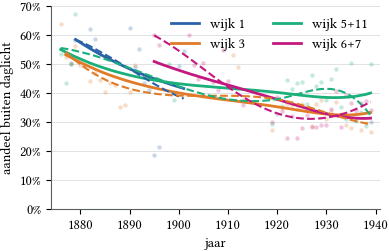

In [19]:
fig, ax = plt.subplots(
    figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.62)
)

for wijk in WIJKEN:
    kleur = KLEUREN[wijk]

    # geobserveerde waarden
    sub = agg[
        (agg["district"] == wijk) &
        (agg["totaal"] >= MIN_N)
    ]

    ax.scatter(
        sub["year"],
        sub["nacht"] / sub["totaal"] * 100,
        s=10,
        color=kleur,
        alpha=0.25,
        linewidth=0,
        zorder=1,
    )

    # hoofdmodel: gemeenschappelijke spline + wijkhelling
    r = resultaten[wijk]

    ax.plot(
        r["jaren"],
        r["med"],
        color=kleur,
        linewidth=2,
        label=LABELS.get(wijk, f"wijk {wijk}"),
        zorder=3,
    )

    # gevoeligheidsmodel: eigen spline per wijk
    rf = resultaten_flex[wijk]

    ax.plot(
        rf["jaren"],
        rf["med"],
        color=kleur,
        linewidth=1.5,
        linestyle="--",
        zorder=4,
    )

ax.set_xlabel("jaar")
ax.set_ylabel("aandeel buiten daglicht")

ax.yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%")
)

ax.set_xlim(1874, 1941)
ax.set_ylim(0, 70)

ax.legend(
    frameon=False,
    ncol=2,
    loc="upper right",
    fontsize=CORPS,
)

opmaak_assen(ax)

plt.show()

In [20]:
idata = model.fit(
    draws=2000,
    tune=3000,
    chains=4,
    cores=1,
    target_accept=0.99,
    random_seed=42,
    idata_kwargs={"log_likelihood": True},
)

print(
    "Aantal divergences:",
    idata.sample_stats["diverging"].sum().item()
)

az.summary(idata)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, Intercept, bs(jaar_c, df=4), 1|district_sigma, 1|district_offset, jaar_c|district_sigma, jaar_c|district_offset]


Output()

Output()

Output()

In [21]:
print(
    "Aantal divergences:",
    idata.sample_stats["diverging"].sum().item()
)

samenvatting = az.summary(idata)

print("maximale R-hat:", samenvatting["r_hat"].max())
print("minimale bulk ESS:", samenvatting["ess_bulk"].min())

Aantal divergences: 0


maximale R-hat: 1.0
minimale bulk ESS: 1333.0


In [22]:
def voorspel_wijk(district):
    van, tot = BEREIK[district]
    jaren = np.arange(van, tot + 1)

    grid = pd.DataFrame({
        "year": jaren,
        "jaar_c": (jaren - 1900) / 10,
        "totaal": 1,
        "district": pd.Categorical(
            [district] * len(jaren),
            categories=agg["district"].cat.categories,
        ),
    })

    pred = model.predict(
        idata,
        data=grid,
        kind="mean",
        inplace=False,
        sample_new_groups=False,
    )

    p = kansen(pred)

    return {
        "jaren": jaren,
        **samenvatten(p),
    }


resultaten = {
    district: voorspel_wijk(district)
    for district in BEREIK
}

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


In [23]:
resultaten = {
    district: voorspel_wijk(district)
    for district in BEREIK
}

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


In [24]:
for wijk in WIJKEN:
    r = resultaten[wijk]

    print(
        f"wijk {wijk}: "
        f"{r['jaren'][0]} = {r['med'][0]:.1f}% "
        f"[{r['lo'][0]:.1f}–{r['hi'][0]:.1f}]  →  "
        f"{r['jaren'][-1]} = {r['med'][-1]:.1f}% "
        f"[{r['lo'][-1]:.1f}–{r['hi'][-1]:.1f}]"
    )

print(
    f"algemene trend: "
    f"{totaal['jaren'][0]} = {totaal['med'][0]:.1f}% "
    f"[{totaal['lo'][0]:.1f}–{totaal['hi'][0]:.1f}]  →  "
    f"{totaal['jaren'][-1]} = {totaal['med'][-1]:.1f}% "
    f"[{totaal['lo'][-1]:.1f}–{totaal['hi'][-1]:.1f}]"
)

wijk 1: 1879 = 58.4% [51.9–64.8]  →  1901 = 41.5% [36.3–46.4]
wijk 3: 1877 = 53.1% [47.9–58.5]  →  1939 = 33.2% [27.7–39.1]
wijk 5: 1876 = 54.9% [47.8–61.8]  →  1939 = 39.8% [33.3–46.3]
wijk 6: 1895 = 51.0% [43.9–58.0]  →  1939 = 31.2% [25.3–37.5]
algemene trend: 1876 = 59.0% [45.9–73.1]  →  1939 = 33.0% [17.7–50.6]


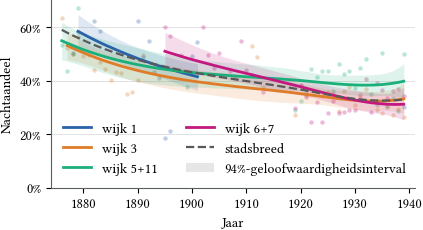

In [25]:
fig, ax = plt.subplots(
    figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.62)
)

for wijk in WIJKEN:
    kleur = KLEUREN[wijk]

    # Geobserveerde jaarwaarden
    sub = agg[
        (agg["district"] == wijk) &
        (agg["totaal"] >= MIN_N)
    ]

    ax.scatter(
        sub["year"],
        sub["nacht"] / sub["totaal"] * 100,
        s=10,
        color=kleur,
        alpha=0.30,
        linewidth=0,
        zorder=1,
    )

    # Gemodelleerde wijktrend
    r = resultaten[wijk]

    ax.fill_between(
        r["jaren"],
        r["lo"],
        r["hi"],
        color=kleur,
        alpha=0.15,
        linewidth=0,
        zorder=2,
    )

    ax.plot(
        r["jaren"],
        r["med"],
        color=kleur,
        linewidth=2,
        label=LABELS.get(wijk, f"wijk {wijk}"),
        zorder=3,
    )

# Algemene modeltrend
ax.plot(
    totaal["jaren"],
    totaal["med"],
    color="0.35",
    linewidth=1.6,
    linestyle="--",
    label="stadsbreed",
    zorder=4,
)

ax.set_xlabel("Jaar")
ax.set_ylabel("Nachtaandeel")

ax.yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%")
)

ax.set_xlim(1874, 1941)
ax.set_ylim(0, 70)

handles, labels = ax.get_legend_handles_labels()

handles.append(Patch(color="0.35", alpha=0.15, linewidth=0))
labels.append("94%-geloofwaardigheidsinterval")

ax.legend(
    handles,
    labels,
    frameon=False,
    ncol=2,
    loc="lower left",
    fontsize=CORPS,
)

opmaak_assen(ax)

fig.tight_layout()

pas_breedte_aan(fig)
fig.savefig(
    UITVOER / "6.11_nachtaandeel_per_wijk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
print(1900 + 10 * agg["jaar_c"].median())

1921.0


In [27]:
# Begin- en eindwaarden per wijk
for wijk in WIJKEN:
    r = resultaten[wijk]
    
    print(
        f"Wijk {wijk}: "
        f"{r['jaren'][0]} = {r['med'][0]:.1f}% "
        f"[{r['lo'][0]:.1f}–{r['hi'][0]:.1f}]  →  "
        f"{r['jaren'][-1]} = {r['med'][-1]:.1f}% "
        f"[{r['lo'][-1]:.1f}–{r['hi'][-1]:.1f}]"
    )

print(
    f"Algemene modeltrend: "
    f"{totaal['jaren'][0]} = {totaal['med'][0]:.1f}% "
    f"[{totaal['lo'][0]:.1f}–{totaal['hi'][0]:.1f}]  →  "
    f"{totaal['jaren'][-1]} = {totaal['med'][-1]:.1f}% "
    f"[{totaal['lo'][-1]:.1f}–{totaal['hi'][-1]:.1f}]"
)

Wijk 1: 1879 = 58.4% [51.9–64.8]  →  1901 = 41.5% [36.3–46.4]
Wijk 3: 1877 = 53.1% [47.9–58.5]  →  1939 = 33.2% [27.7–39.1]
Wijk 5: 1876 = 54.9% [47.8–61.8]  →  1939 = 39.8% [33.3–46.3]
Wijk 6: 1895 = 51.0% [43.9–58.0]  →  1939 = 31.2% [25.3–37.5]
Algemene modeltrend: 1876 = 59.0% [45.9–73.1]  →  1939 = 33.0% [17.7–50.6]


In [28]:
GIS = Path("../../data/algemeen/gis")

PAD_WIJKEN = GIS / "wijken"
PAD_BEBOUWING = GIS / "bebouwing"

wijken_1886 = gpd.read_file(
    PAD_WIJKEN / "wijken_1886-1901.shp"
)

wijken_1921 = gpd.read_file(
    PAD_WIJKEN / "wijken_1921-1944.shp"
)

bebouwing_1886 = gpd.read_file(
    PAD_BEBOUWING / "bebouwing_1886.shp"
)

bebouwing_1908 = gpd.read_file(
    PAD_BEBOUWING / "bebouwing_1908.shp"
)

vesting_1866 = gpd.read_file(
    PAD_BEBOUWING / "vesting_1886.shp"
)

fort_1908 = gpd.read_file(
    PAD_BEBOUWING / "vesting_1908.shp"
)

water_1886 = gpd.read_file(
    PAD_BEBOUWING / "water_1886.shp"
)

water_1908 = gpd.read_file(
    PAD_BEBOUWING / "water_1908.shp"
)


# ------------------------------------------------------------
# Zelfde CRS
# ------------------------------------------------------------

for gdf in [
    wijken_1921,
    bebouwing_1886,
    bebouwing_1908,
    vesting_1866,
    fort_1908,
    water_1886,
    water_1908,
]:
    gdf.to_crs(wijken_1886.crs, inplace=True)



In [29]:
data_1886 = ["1", "3", "5", "6"]
data_1921 = ["3", "5", "6", "7", "11"]

wijken_1886_sel = wijken_1886[
    wijken_1886["SectionNr"].isin(data_1886)
].copy()

wijken_1921_sel = wijken_1921[
    wijken_1921["Section_Nr"].isin(data_1921)
].copy()

In [30]:
wijken_1886_zonder9 = wijken_1886[
    wijken_1886["SectionNr"] != "9"
].copy()

wijken_1921_zonder9 = wijken_1921[
    wijken_1921["Section_Nr"] != "9"
].copy()

bebouwing_1886_binnen = gpd.clip(
    bebouwing_1886,
    wijken_1886_zonder9.dissolve()
)

bebouwing_1908_binnen = gpd.clip(
    bebouwing_1908,
    wijken_1921_zonder9.dissolve()
)

In [31]:
bounds_vroeg = vesting_1866.total_bounds
bounds_laat = fort_1908.total_bounds

xmin = min(bounds_vroeg[0], bounds_laat[0])
ymin = min(bounds_vroeg[1], bounds_laat[1])
xmax = max(bounds_vroeg[2], bounds_laat[2])
ymax = max(bounds_vroeg[3], bounds_laat[3])

In [32]:
KLEUREN_KAART = {
    1: KLEUREN[1],
    3: KLEUREN[3],
    5: KLEUREN[5],
    11: KLEUREN[5],
    6: KLEUREN[6],
    7: KLEUREN[6],
}

KLEUR_BEBOUWING = "#D0D0D0"
KLEUR_WATER = "#DCE5E8"
KLEUR_OMWALLING = "#999999"

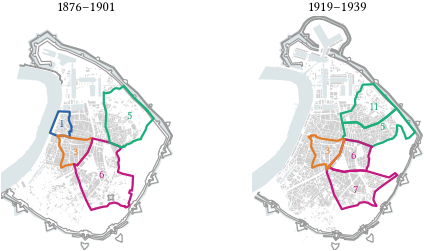

In [33]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.58),
)

panelen = [
    (
        axes[0],
        wijken_1886_sel,
        bebouwing_1886_binnen,
        vesting_1866,
        water_1886,
        "SectionNr",
        "1876–1901",
    ),
    (
        axes[1],
        wijken_1921_sel,
        bebouwing_1908_binnen,
        fort_1908,
        water_1908,
        "Section_Nr",
        "1919–1939",
    ),
]


for ax, wijken_sel, bebouwing, omwalling, water, nr_col, titel in panelen:

    # achtergrond
    water.plot(
        ax=ax,
        color=KLEUR_WATER,
        linewidth=0,
        zorder=0,
    )

    bebouwing.plot(
        ax=ax,
        color=KLEUR_BEBOUWING,
        linewidth=0,
        zorder=1,
    )

    omwalling.plot(
        ax=ax,
        color="none",
        edgecolor=KLEUR_OMWALLING,
        linewidth=0.8,
        zorder=2,
    )

    # geselecteerde wijken
    for _, row in wijken_sel.iterrows():

        wijk = int(row[nr_col])
        kleur = KLEUREN_KAART[wijk]

        gpd.GeoSeries(
            [row.geometry],
            crs=wijken_sel.crs,
        ).plot(
            ax=ax,
            color="none",
            edgecolor=kleur,
            linewidth=1.6,
            zorder=3,
        )

        punt = row.geometry.representative_point()

        ax.annotate(
            str(wijk),
            xy=(punt.x, punt.y),
            ha="center",
            va="center",
            fontsize=CORPS_KLEIN,
            color=kleur,
            fontweight="bold",
            fontfamily=FONT_CIJFERS,
            zorder=4,
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ax.set_title(
        titel,
        fontsize=CORPS,
        fontfamily=FONT_TEKST,
        pad=4,
    )

    ax.set_axis_off()


fig.subplots_adjust(
    left=0,
    right=1,
    bottom=0,
    top=0.95,
    wspace=0.03,
)

pas_breedte_aan(fig)
fig.savefig(
    UITVOER / "6.12_wijkenkaart.png",
    dpi=300,
)

plt.show()

In [34]:
fits = {}
for k in [3, 4, 5, 6, 8]:
    m = bmb.Model(
        f"p(nacht, totaal) ~ bs(jaar_c, df={k}) + (jaar_c | district)",
        data=agg,
        family="beta_binomial",
    )
    fits[f"df={k}"] = m.fit(
        draws=2000, tune=3000, chains=4, cores=1,
        target_accept=0.99, random_seed=42,
        idata_kwargs={"log_likelihood": True},
    )

vergelijking = az.compare(fits, ic="loo")
print(vergelijking[["rank", "elpd_loo", "elpd_diff", "dse", "warning"]])

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, Intercept, bs(jaar_c, df=3), 1|district_sigma, 1|district_offset, jaar_c|district_sigma, jaar_c|district_offset]


Output()

Output()

Output()

Output()

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(
/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/bambi/models.py:851: FutureWarning: 'mean' has been replaced by 'response_params' and is not going to work in the future
  warnings.warn(


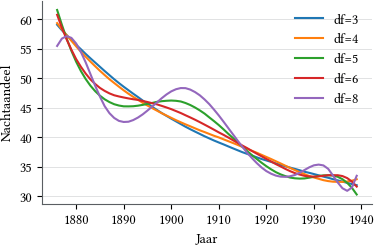

In [35]:
fig, ax = plt.subplots(figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.62))

grid = pd.DataFrame({
    "year": JAREN,
    "jaar_c": (JAREN - 1900) / 10,
    "totaal": 1,
    "district": pd.Categorical(
        [agg["district"].cat.categories[0]] * len(JAREN),
        categories=agg["district"].cat.categories,
    ),
})

for k in [3, 4, 5, 6, 8]:
    m = bmb.Model(
        f"p(nacht, totaal) ~ bs(jaar_c, df={k}) + (jaar_c | district)",
        data=agg,
        family="beta_binomial",
    )
    m.build()
    pred = m.predict(fits[f"df={k}"], data=grid, kind="mean",
                     inplace=False, include_group_specific=False)
    ax.plot(JAREN, np.median(kansen(pred), axis=1), label=f"df={k}")

ax.set_xlabel("Jaar")
ax.set_ylabel("Nachtaandeel")
ax.legend(frameon=False, fontsize=CORPS)
opmaak_assen(ax)
plt.show()